# 프로젝트 : 이름은 달라도 같은 위키, Jev로 찾아 병합하기

한양대 ERICA x 모두의연구소 자연어처리(중급) Project 1

- 코더: 박서준

## 문제 정의
---
노트를 AI가 읽고 주제별 위키로 정리해 주는 세컨드브레인을 쓰고 있는데 노트가 쌓이자 같은 대상이 이름만 다른 위키 두 장으로 갈라지는 문제가 보였다. 어떤 날은 「러닝」, 다른 날은 「달리기」라고 적으면 AI가 둘을 다른 주제로 보고 따로 만든다. 그러면 기록이 두 곳에 흩어져서 어느 쪽을 봐도 반쪽이고, 질문에 대한 답도 반쪽이 된다. 중복을 찾아내도 합치는 일은 결국 내가 손으로 해야 했다.

## 가설 수립
---
"이름이 달라도 같은 대상인 위키를 AI가 판단해서 찾고 버튼 한 번으로 병합하게 하면, 정리되는 중복이 늘고 그 대상에 대한 답이 더 많은 기록을 담고 유저의 편의성은 올라간다."

지표는 셋이다.

1. 찾은 중복 가운데 실제로 정리된 비율
2. 병합 전후로 같은 질문을 던졌을 때 답에 담긴 요점 수
3. 병합을 되돌린 비율

## 해결 방안
---
판단은 Jev가, 글쓰기는 claude api, 근거와 파일을 지키는 일은 코드가 맡는다. Jev는 "두 페이지가 같은 대상인가"에 확률로 답한다. 그래서 글자가 비슷한 반대 개념(교감신경과 부교감신경)은 거르고, 이름이 다른 같은 대상(러닝과 달리기)은 잡는다. 병합을 누르면 코드가 두 페이지의 기록을 하나도 버리지 않고 모으고, 없어지는 이름은 별칭으로 남겨 기존 링크를 그대로 잇는다. 글쓰기 AI는 모은 기록만 근거로 한 장으로 다시 쓰고, Jev가 문장마다 근거가 있는지 다시 확인한다. 사용자는 미리보기를 보고 확인하고, 언제든 되돌릴 수 있다.

## 실험 개요
---
가설을 그대로 재려면 실제 사용자가 필요하다. 이번에는 사용자 없이 확인할 수 있는 세 가지를 먼저 확인했다.

- RQ1. 글자가 얼마나 겹치는지(글자 유사도)만으로 같은 대상인 위키를 찾을 수 있는가? Jev 판정은 무엇을 바꾸는가?
- RQ2. 병합하면 그 대상에 대한 질문에 쓸 수 있는 요점(기록)이 늘어나는가? (지표 2)
- RQ3. 글쓰기 AI가 다시 쓴 글에 근거 없는 문장이 섞이면 Jev 근거 확인이 잡아내는가?

지표 1(정리된 비율)과 지표 3(되돌린 비율)은 사용자의 행동 기록이 있어야 잴 수 있어서, 계산 코드만 만들고 예시 기록으로 돌려 봤다.

데이터는 공개 저장소라 직접 지어낸 위키 12장이다. 같은 대상인 쌍 3개(러닝/달리기, 코테/코딩 테스트, 자소서/자기소개서)와, 글자는 비슷하지만 다른 개념인 쌍 3개(교감신경/부교감신경, 인플레이션/디플레이션, 과적합/과소적합)를 일부러 넣었다.

## 1) 준비
---
API 키는 코드에 적지 않고 환경 변수에서만 읽는다. Jev와 Claude의 답은 `cache/` 폴더에 저장해서, 키가 없는 사람도 같은 결과로 노트북을 다시 돌릴 수 있게 했다.

In [1]:
import copy
import hashlib
import json
import math
import os
import shutil
import subprocess
import urllib.request
from collections import Counter
from dataclasses import dataclass, field
from itertools import combinations
from pathlib import Path

import anthropic
import pandas as pd
from IPython.display import Image, display

JEV_URL = "https://api.typesafe.ai/v1/systemone"
JEV_MODEL = "jev-1.13.0"  # 판을 고정한다. latest 는 새 판이 나오면 답이 바뀐다.
WRITER_MODEL = "claude-haiku-5-5"
SAME_THRESHOLD = 0.5  # Jev 가 '같은 대상'이라고 볼 확률의 문턱
CACHE_DIR = Path("cache")
CACHE_DIR.mkdir(exist_ok=True)

print("anthropic SDK", anthropic.__version__)
print("Jev 키:", "있음" if os.environ.get("TYPESAFE_API_KEY") else "없음")
print("Claude Code CLI:", "있음" if shutil.which("claude") else "없음")

anthropic SDK 2.8.0
Jev 키: 없음
Claude Code CLI: 있음


## 목업
---
아이디어가 화면에서 어떻게 보이는지 먼저 그렸다. 1 → 2 → 3 순서로 쓰고, 마지막 그림은 누가 무엇을 맡는지 보여 준다.

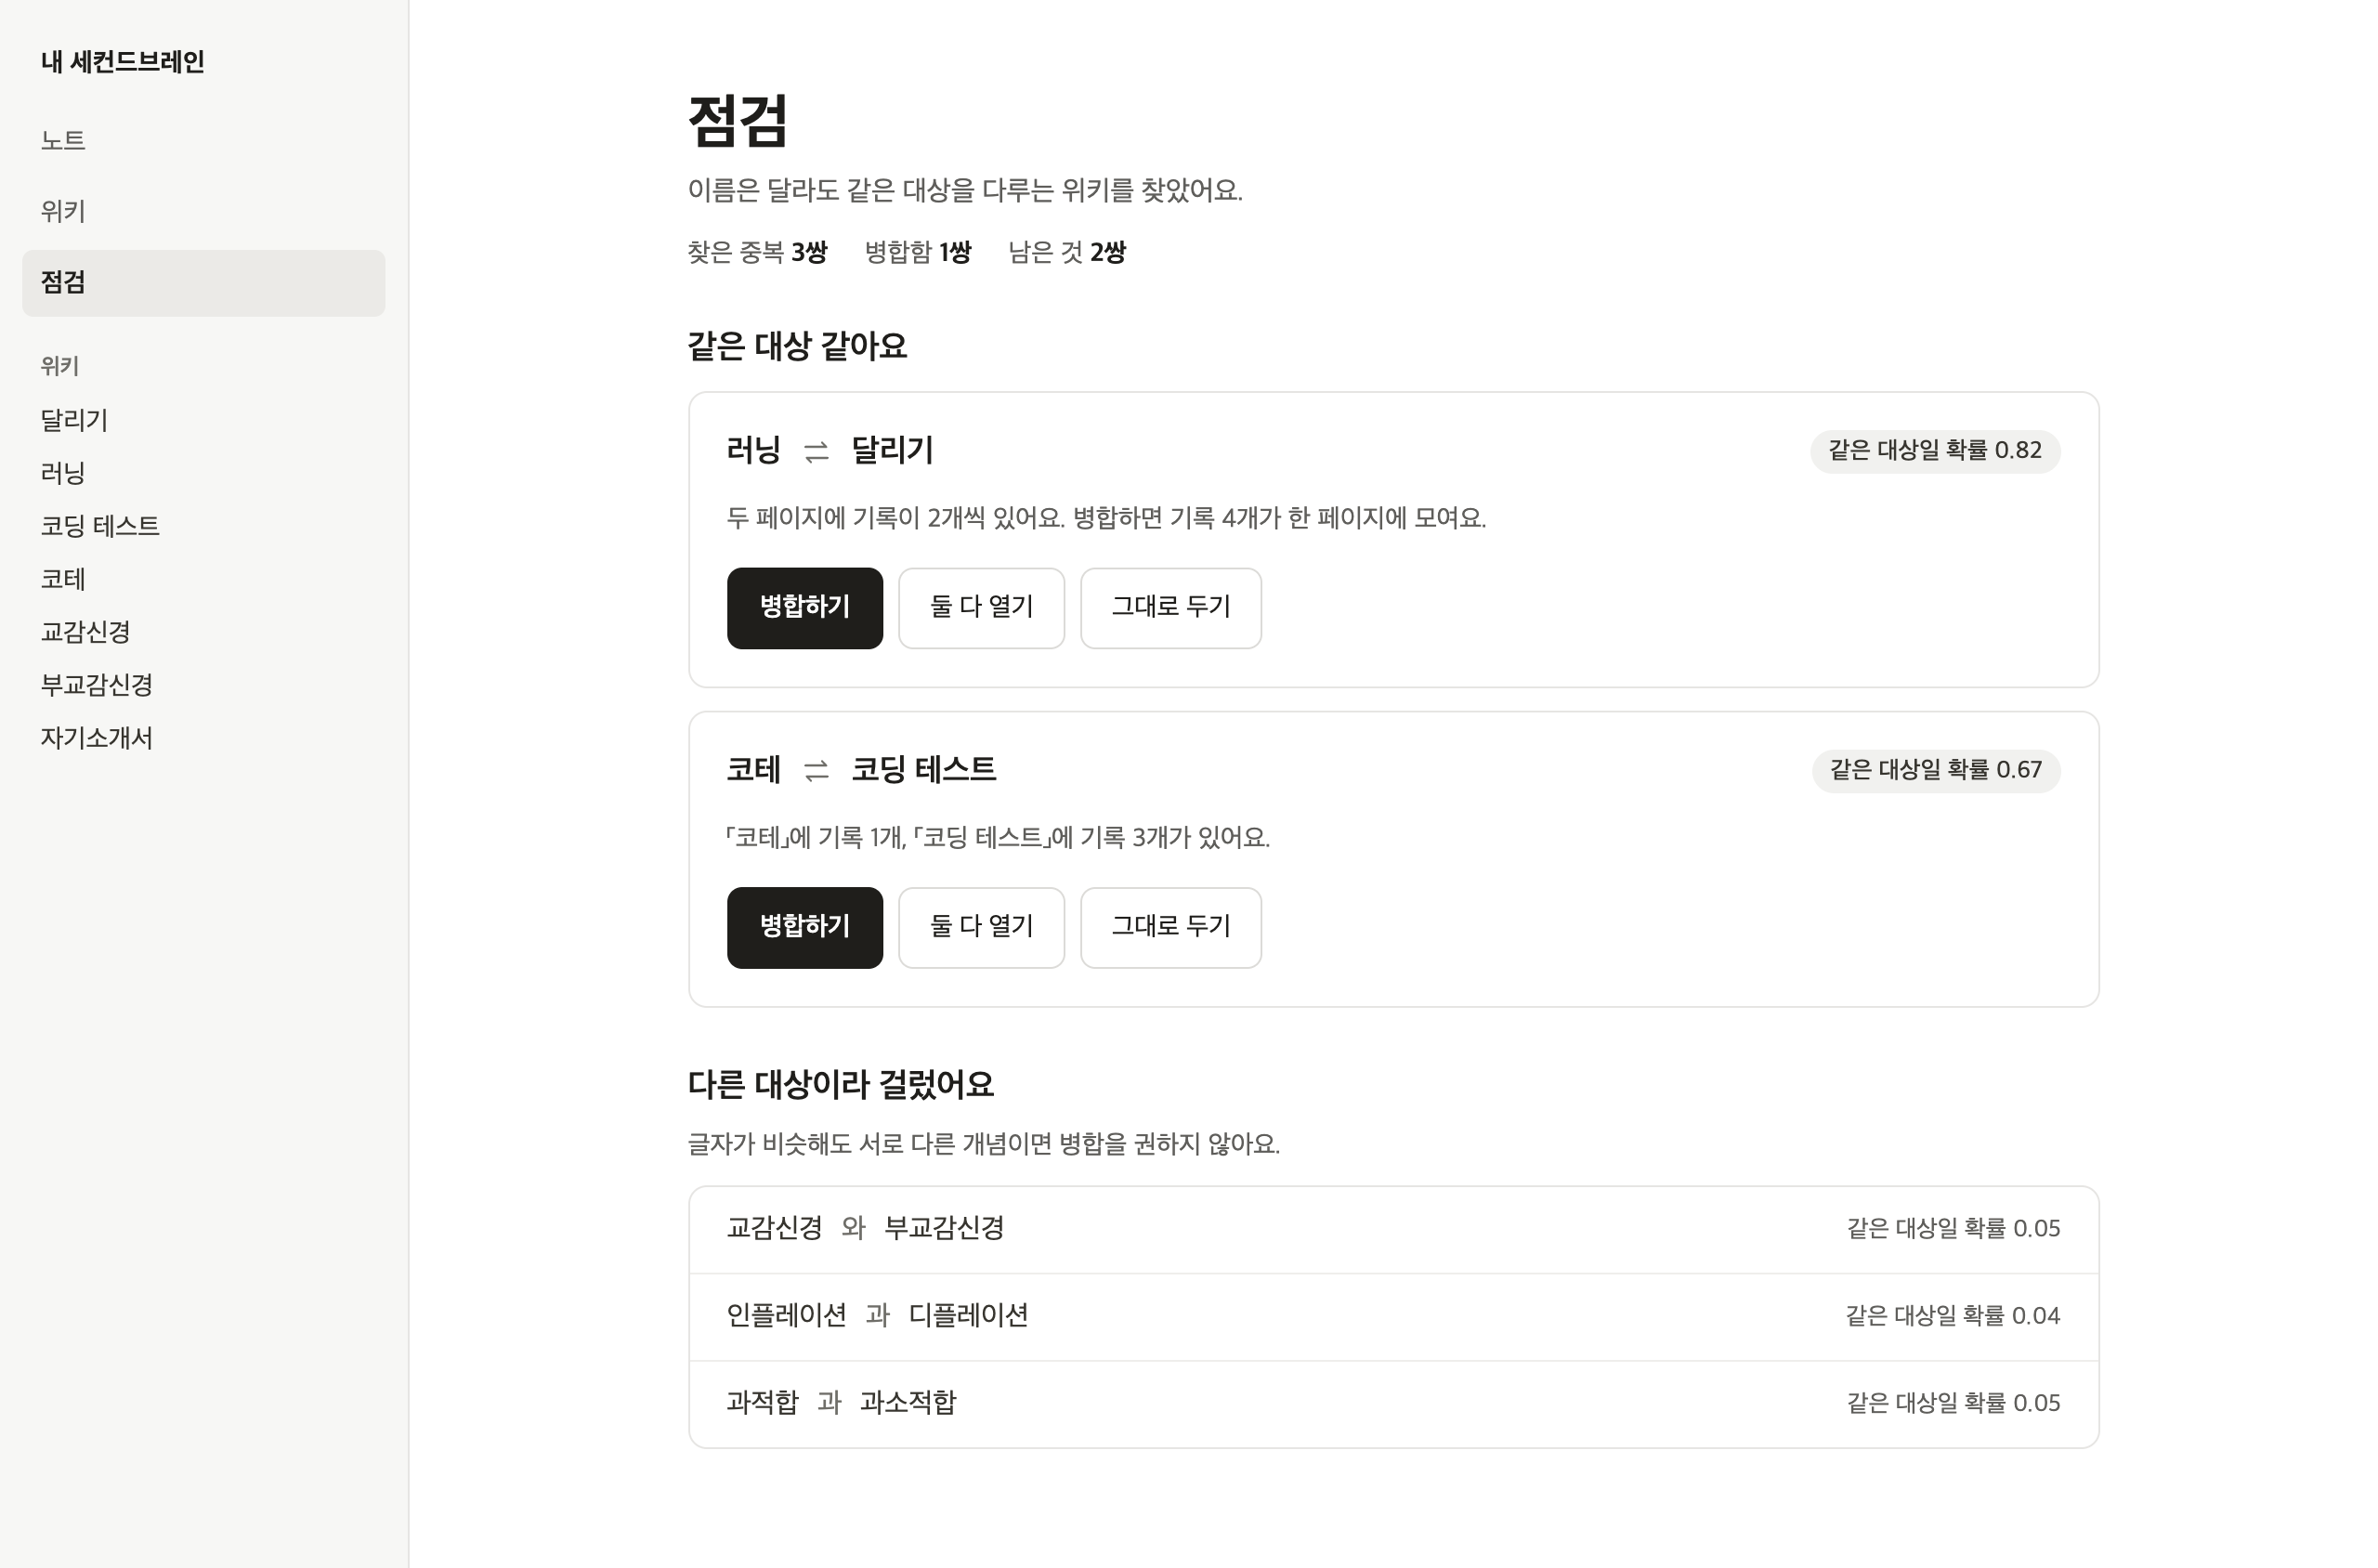

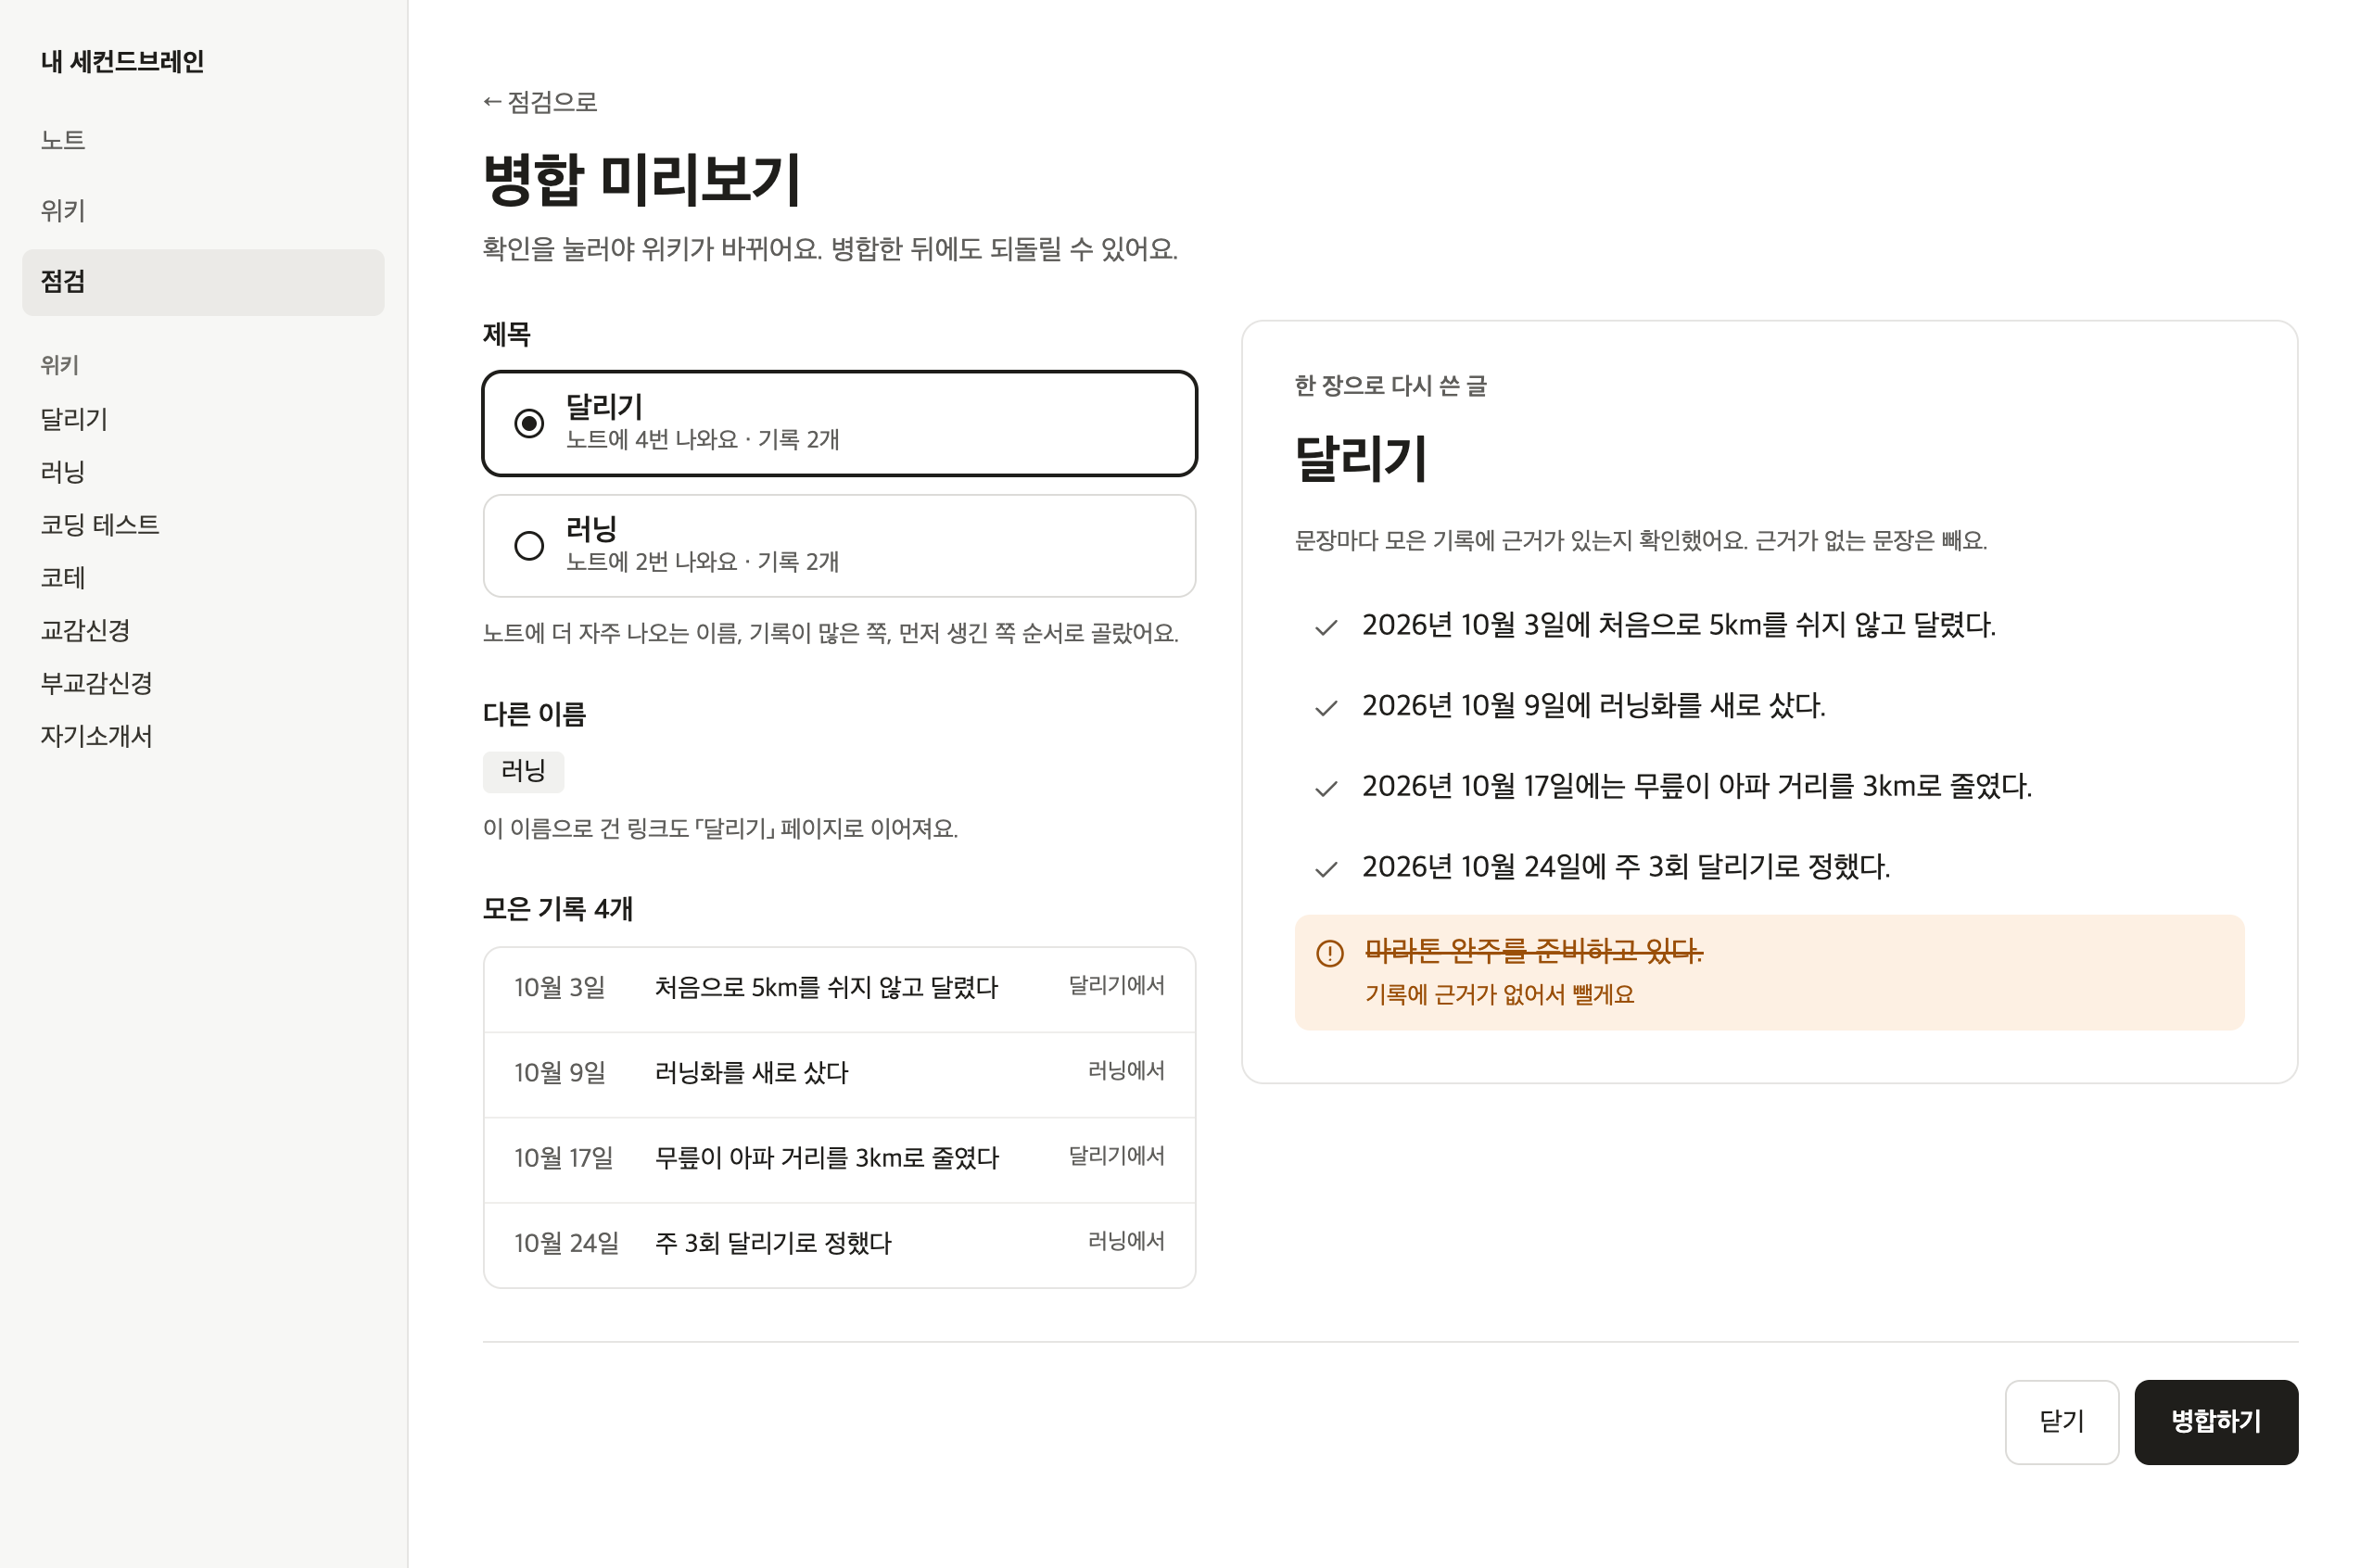

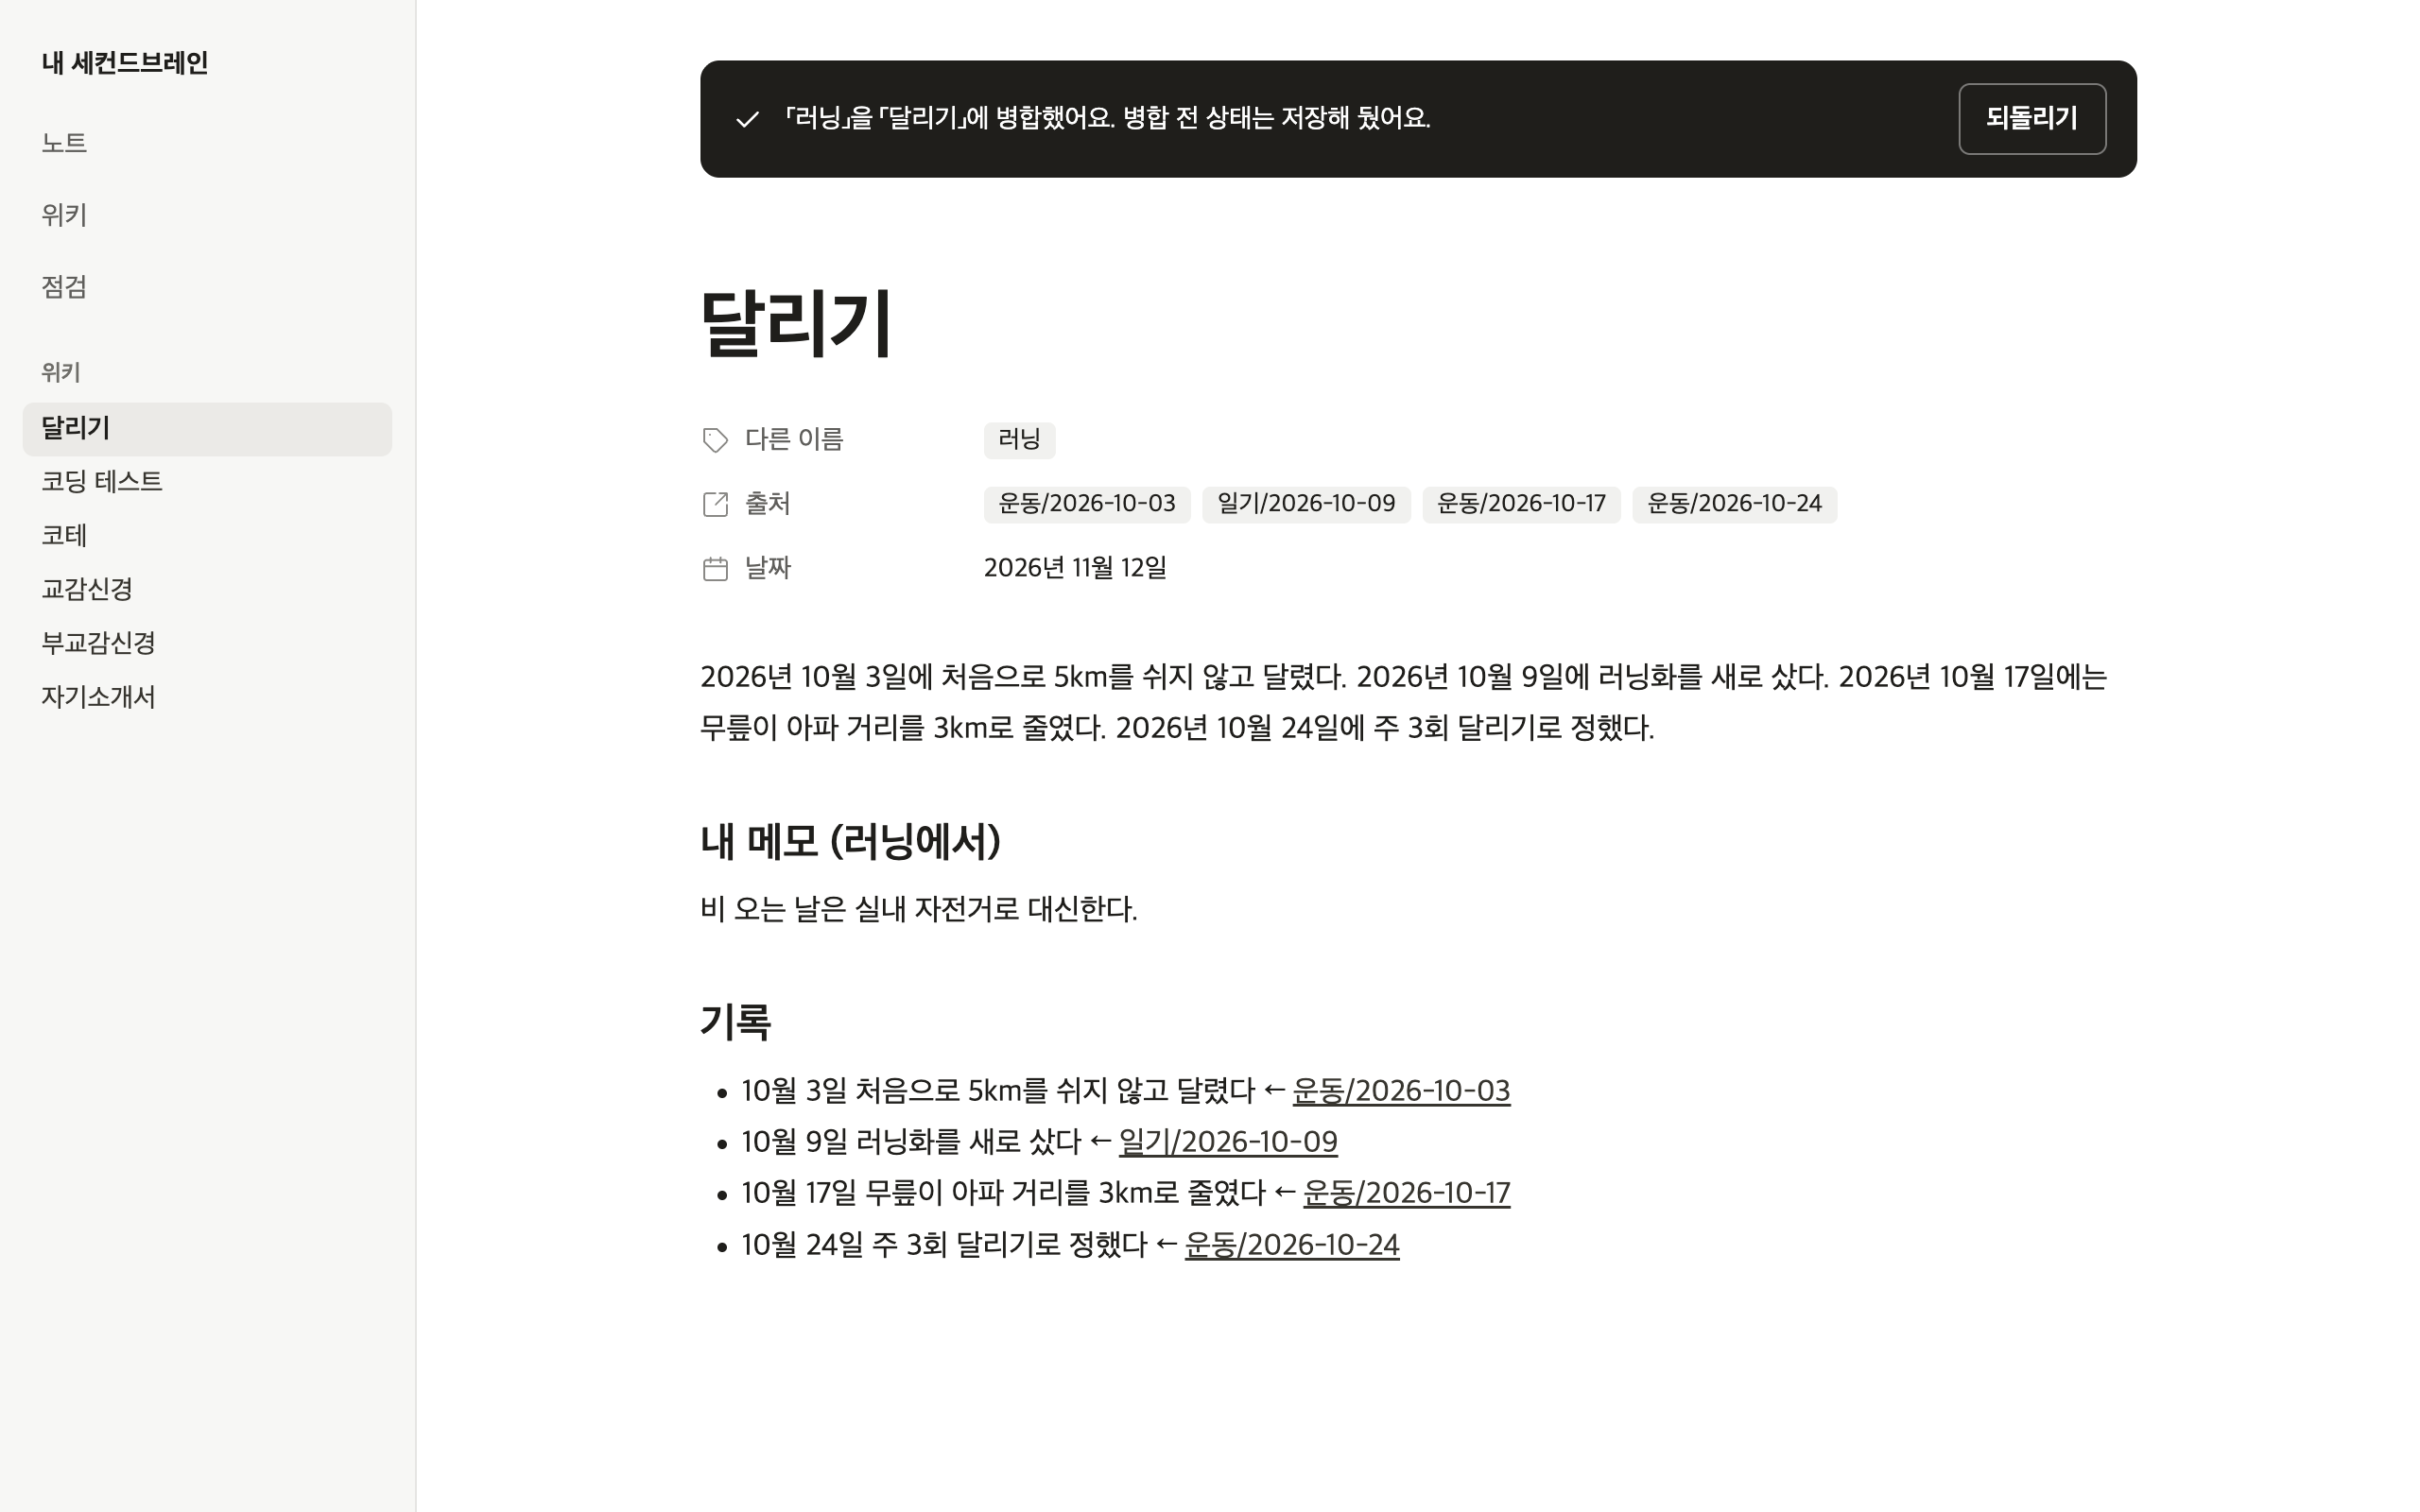

In [2]:
for name in ["01_find", "02_preview", "03_done"]:
    display(Image(filename=f"images/{name}.png", width=900))

화면 1은 4절의 판정 결과, 화면 2와 3은 5~8절에서 「달리기」와 「러닝」을 병합한 결과를 그대로 옮겼다. 확률, 문장, 기록은 모두 아래 실행 결과에서 나온 값이다. 화면 2에서 지운 「마라톤 완주를 준비하고 있다」는 7절에서 시험하려고 일부러 넣은 문장이고, Claude가 실제로 쓴 문장은 모두 근거 확인을 통과했다. 화면 2의 제목은 목업에서 눌러 바꿀 수 있게 만들었고, 여기에는 첫 상태만 실었다.

## 2) 데이터: 지어낸 위키 12장과 노트
---
위키 페이지는 이름, 만든 날, 기록 줄로 이루어진다. 기록 줄은 위키 문장의 근거라서 병합할 때 하나도 버리면 안 된다. `user_sections` 는 사용자가 손으로 고친 절이다.

In [3]:
@dataclass
class Record:
    """위키 페이지의 기록 한 줄. 위키 문장의 근거가 된다."""

    date: str
    text: str
    source: str  # 이 기록을 뽑아 온 노트


@dataclass
class WikiPage:
    """AI가 노트에서 만든 위키 페이지 한 장."""

    name: str
    created: str
    records: list[Record]
    aliases: list[str] = field(default_factory=list)
    # 사용자가 손으로 고친 절. AI가 다시 쓰지 않고 그대로 옮긴다.
    user_sections: dict[str, str] = field(default_factory=dict)

    def body(self) -> str:
        """판정에 넘길 본문. 제목과 기록 줄을 잇는다."""
        lines = [f"# {self.name}", ""]
        lines += [f"- {r.date} {r.text}" for r in self.records]
        return "\n".join(lines)


def page(name, created, records, **kw):
    """(날짜, 기록, 노트) 튜플 목록으로 WikiPage 를 만든다."""
    return WikiPage(name, created, [Record(*r) for r in records], **kw)


PAGES = [
    page("달리기", "2026-10-03", [
        ("2026-10-03", "처음으로 5km를 쉬지 않고 달렸다", "운동/2026-10-03"),
        ("2026-10-17", "무릎이 아파 거리를 3km로 줄였다", "운동/2026-10-17"),
    ]),
    page("러닝", "2026-10-09", [
        ("2026-10-09", "러닝화를 새로 샀다", "일기/2026-10-09"),
        ("2026-10-24", "주 3회 달리기로 정했다", "운동/2026-10-24"),
    ], user_sections={"내 메모": "비 오는 날은 실내 자전거로 대신한다."}),
    page("코딩 테스트", "2026-09-20", [
        ("2026-09-20", "백준 실버 문제를 하루 두 개씩 풀기로 했다",
         "공부/2026-09-20"),
        ("2026-10-02", "모의 시험에서 시간 초과가 두 번 났다", "공부/2026-10-02"),
        ("2026-10-15", "그리디 문제를 다시 풀었다", "공부/2026-10-15"),
    ]),
    page("코테", "2026-10-11", [
        ("2026-10-11", "카카오 1번은 문자열 처리 문제였다", "일기/2026-10-11"),
    ]),
    page("자기소개서", "2026-09-28", [
        ("2026-09-28", "지원 동기를 500자로 줄였다", "취업/2026-09-28"),
        ("2026-10-05", "동아리 경험을 첫 문단에 넣었다", "취업/2026-10-05"),
    ]),
    page("자소서", "2026-10-20", [
        ("2026-10-20", "첨삭을 받고 성장 과정을 다시 썼다", "취업/2026-10-20"),
    ]),
    page("교감신경", "2026-09-10", [
        ("2026-09-10", "위급할 때 심장 박동을 빠르게 한다", "생리학/2주차"),
        ("2026-09-10", "흥분하면 동공이 커진다", "생리학/2주차"),
    ]),
    page("부교감신경", "2026-09-10", [
        ("2026-09-10", "쉴 때 심장 박동을 느리게 한다", "생리학/2주차"),
        ("2026-09-10", "소화를 돕는다", "생리학/2주차"),
    ]),
    page("인플레이션", "2026-09-15", [
        ("2026-09-15", "물가가 계속 오르는 현상이다", "경제학/3주차"),
        ("2026-09-15", "돈의 가치가 떨어진다", "경제학/3주차"),
    ]),
    page("디플레이션", "2026-09-15", [
        ("2026-09-15", "물가가 계속 내리는 현상이다", "경제학/3주차"),
        ("2026-09-15", "소비가 줄고 경기가 나빠질 수 있다", "경제학/3주차"),
    ]),
    page("과적합", "2026-10-08", [
        ("2026-10-08", "학습 데이터에는 잘 맞지만 새 데이터에서 성능이 떨어진다",
         "딥러닝/6주차"),
        ("2026-10-08", "검증 손실이 다시 오르면 의심한다", "딥러닝/6주차"),
    ]),
    page("과소적합", "2026-10-08", [
        ("2026-10-08", "학습 데이터에서도 성능이 낮다", "딥러닝/6주차"),
        ("2026-10-08", "모델이 너무 단순하면 생긴다", "딥러닝/6주차"),
    ]),
]
WIKI = {p.name: p for p in PAGES}

# 정답: 이름은 다르지만 같은 대상인 쌍
SAME_PAIRS = {
    frozenset(("달리기", "러닝")),
    frozenset(("코딩 테스트", "코테")),
    frozenset(("자기소개서", "자소서")),
}

# 사용자가 실제로 쓴 노트(위키를 만든 원문). 제목을 고를 때 쓴다.
NOTES = {
    "운동/2026-10-03": "오늘 처음으로 5km를 쉬지 않고 달렸다. 달리기 끝나고 스트레칭.",
    "일기/2026-10-09": "러닝화를 새로 샀다. 이제 달리기가 더 재밌을 것 같다.",
    "운동/2026-10-17": "무릎이 아파서 3km로 줄였다. 달리기 전에 몸을 더 풀자.",
    "운동/2026-10-24": "주 3회 달리기로 정했다. 러닝 크루도 알아보기.",
    "공부/2026-09-20": "코테 대비로 백준 실버 문제를 하루 두 개씩 풀기로 했다.",
    "공부/2026-10-02": "코테 모의 시험에서 시간 초과가 두 번 났다.",
    "일기/2026-10-11": "카카오 코테 1번은 문자열 처리. 코딩 테스트는 결국 구현력.",
    "공부/2026-10-15": "그리디 문제를 다시 풀었다.",
    "취업/2026-09-28": "자기소개서 지원 동기를 500자로 줄였다.",
    "취업/2026-10-05": "동아리 경험을 첫 문단에 넣었다.",
    "취업/2026-10-20": "자소서 첨삭을 받고 성장 과정을 다시 썼다.",
}

print(f"위키 {len(WIKI)}장, 쌍 {len(list(combinations(WIKI, 2)))}개,"
      f" 정답 쌍 {len(SAME_PAIRS)}개, 노트 {len(NOTES)}개")

위키 12장, 쌍 66개, 정답 쌍 3개, 노트 11개


## 3) Jev 부르기
---
Jev(TypeSafe)는 글을 쓰지 않고 판단만 하는 모델이다. 판단할 글(`state`)과 질문을 받아서 Noul 질문이면 '예'일 확률(0~1)만 돌려준다. 공식 SDK가 없어서 HTTP로 직접 부른다.

In [4]:
def _cache_key(payload: dict) -> str:
    raw = json.dumps(payload, ensure_ascii=False, sort_keys=True)
    return hashlib.sha256(raw.encode("utf-8")).hexdigest()


class CachedCaller:
    """같은 요청은 한 번만 보내고 답을 JSON 파일에 남긴다.

    API 키가 없는 사람(리뷰어)도 저장된 답으로 노트북을 끝까지 돌릴 수 있게
    하려는 것이다. live 는 실제로 보낸 요청 수, hits 는 파일에서 꺼낸 수다.
    """

    def __init__(self, path: Path):
        self.path = path
        self.store = json.loads(path.read_text()) if path.exists() else {}
        self.live = 0
        self.hits = 0

    def call(self, payload: dict, send) -> dict:
        key = _cache_key(payload)
        if key in self.store:
            self.hits += 1
            return self.store[key]
        result = send(payload)
        self.live += 1
        self.store[key] = result
        self.path.write_text(
            json.dumps(self.store, ensure_ascii=False, indent=1))
        return result


JEV_CACHE = CachedCaller(CACHE_DIR / "jev.json")


def _post_jev(payload: dict) -> dict:
    key = os.environ.get("TYPESAFE_API_KEY")
    if not key:
        raise RuntimeError("TYPESAFE_API_KEY 가 없고 cache 에도 없는 요청이다")
    req = urllib.request.Request(
        JEV_URL,
        data=json.dumps(payload).encode("utf-8"),
        headers={"Authorization": f"Bearer {key}",
                 "Content-Type": "application/json"},
    )
    with urllib.request.urlopen(req, timeout=60) as resp:
        return json.load(resp)


def jev_noul(state: dict, instructions: str, criteria: dict) -> float:
    """Jev 에 예/아니오 질문 하나를 묻고 '예'일 확률을 돌려준다.

    state 는 판단할 글, criteria 는 무엇을 예/아니오로 볼지 적은 기준이다.
    """
    payload = {
        "model": JEV_MODEL,
        "state": state,
        "questions": {"q": {"type": "noul", "instructions": instructions,
                            "criteria": criteria}},
    }
    answer = JEV_CACHE.call(payload, _post_jev)
    return answer["answers"]["q"]["noul"]

## 4) RQ1: 글자 유사도와 Jev 판정 비교
---
비교 기준은 글자 유사도다. 두 글자씩 끊은 조각(bigram)으로 TF-IDF 벡터를 만들고 코사인 유사도를 쟀다. 한국어는 띄어쓰기와 조사가 흔들려서 낱말보다 글자 조각이 안정적이다.

Jev 에는 "두 페이지가 같은 대상이라 하나로 합쳐야 하는가"를 묻는다. 기준에 「한쪽이 다른 쪽의 일부·원인·사례이거나 관련만 있으면 아니오」를 넣어서, 관련 있는 개념과 같은 개념을 가르게 했다. 12장에서 나오는 66쌍을 모두 물었다.

In [5]:
def bigram_tfidf(docs: dict[str, str]) -> dict[str, dict[str, float]]:
    """문서마다 글자 bigram TF-IDF 벡터(정규화된 dict)를 만든다."""
    tfs = {}
    for name, text in docs.items():
        t = "".join(text.split())  # 띄어쓰기 차이를 없앤다
        tfs[name] = Counter(t[i:i + 2] for i in range(len(t) - 1))
    df = Counter(g for tf in tfs.values() for g in tf)
    n = len(docs)
    vecs = {}
    for name, tf in tfs.items():
        w = {g: (1 + math.log(f)) * math.log(n / df[g]) for g, f in tf.items()}
        norm = math.sqrt(sum(x * x for x in w.values())) or 1.0
        vecs[name] = {g: x / norm for g, x in w.items()}
    return vecs


def cosine(a: dict[str, float], b: dict[str, float]) -> float:
    return sum(x * b.get(g, 0.0) for g, x in a.items())


SAME_QUESTION = ("`page_a` 와 `page_b` 는 같은 대상을 다루는 위키 페이지라서 "
                 "하나로 합쳐야 하는가?")
SAME_CRITERIA = {
    "true": ("두 페이지가 같은 사람, 사물, 개념, 활동, 작품을 다룬다. 이름이 달라도"
             "(동의어, 줄임말, 영어 이름, 띄어쓰기 차이) 같은 대상이면 예다"),
    "false": ("두 페이지가 서로 다른 대상을 다룬다. 한쪽이 다른 쪽의 일부, 도구, "
              "원인, 사례이거나 관련만 있는 경우도 아니오다"),
}


def judge_same(a: WikiPage, b: WikiPage) -> float:
    """두 페이지가 같은 대상일 확률(Jev)."""
    return jev_noul({"page_a": a.body(), "page_b": b.body()},
                    SAME_QUESTION, SAME_CRITERIA)


OPPOSITE_PAIRS = {
    frozenset(("교감신경", "부교감신경")),
    frozenset(("인플레이션", "디플레이션")),
    frozenset(("과적합", "과소적합")),
}

vecs = bigram_tfidf({n: p.body() for n, p in WIKI.items()})
rows = []
for a, b in combinations(WIKI, 2):
    names = frozenset((a, b))
    label = ("같은 대상" if names in SAME_PAIRS
             else "반대 개념" if names in OPPOSITE_PAIRS else "")
    rows.append({
        "쌍": f"{a} / {b}",
        "names": names,
        "글자 유사도": round(cosine(vecs[a], vecs[b]), 3),
        "Jev": judge_same(WIKI[a], WIKI[b]),
        "정답": label,
    })
table = (pd.DataFrame(rows)
         .sort_values("글자 유사도", ascending=False, ignore_index=True))
table.index += 1  # 글자 유사도 순위
print(f"Jev 요청: 실제 {JEV_CACHE.live}번, 저장된 답 {JEV_CACHE.hits}번")
print("글자 유사도 상위 10쌍과, 정답·반대 개념 쌍의 순위")
shown = table.head(10).index.union(table[table["정답"] != ""].index)
table.loc[shown, ["쌍", "글자 유사도", "Jev", "정답"]]

Jev 요청: 실제 0번, 저장된 답 66번
글자 유사도 상위 10쌍과, 정답·반대 개념 쌍의 순위


,쌍,글자 유사도,Jev,정답
1,인플레이션 / 디플레이션,0.340,0.04,반대 개념
2,과적합 / 과소적합,0.301,0.05,반대 개념
3,교감신경 / 부교감신경,0.288,0.05,반대 개념
4,인플레이션 / 과적합,0.086,0.01,
5,코딩 테스트 / 코테,0.051,0.67,같은 대상
6,자기소개서 / 자소서,0.047,0.78,같은 대상
7,달리기 / 러닝,0.043,0.82,같은 대상
8,달리기 / 자기소개서,0.043,0.04,
9,러닝 / 코딩 테스트,0.039,0.03,
10,교감신경 / 인플레이션,0.033,0.01,


In [6]:
def evaluate(pred: set) -> dict:
    """예측한 쌍 집합을 정답 쌍과 비교한다."""
    tp = len(pred & SAME_PAIRS)
    return {"찾음": len(pred), "맞음": tp, "잘못 찾음": len(pred) - tp,
            "놓침": len(SAME_PAIRS) - tp}


jev_pred = {r["names"] for r in rows if r["Jev"] >= SAME_THRESHOLD}

# 글자 유사도로 정답 3쌍을 모두 잡으려면 문턱을 가장 낮은 정답 쌍까지 내려야 한다
min_true_sim = min(r["글자 유사도"] for r in rows if r["names"] in SAME_PAIRS)
text_pred = {r["names"] for r in rows if r["글자 유사도"] >= min_true_sim}

pd.DataFrame([
    {"방법": "Jev (확률 0.5 이상)", **evaluate(jev_pred)},
    {"방법": f"글자 유사도 ({min_true_sim} 이상)", **evaluate(text_pred)},
]).set_index("방법")

,찾음,맞음,잘못 찾음,놓침
방법,,,,
Jev (확률 0.5 이상),3,3,0,0
글자 유사도 (0.043 이상),8,3,5,0


글자 유사도 1~3위는 모두 반대 개념 쌍(0.288~0.340)이었다. 정답 세 쌍은 5~7위(0.043~0.051)로, 아무 관계 없는 「인플레이션 / 과적합」(0.086)보다도 낮았다. 정답 세 쌍을 모두 잡으려고 문턱을 0.043까지 내리면 8쌍을 찾고 그중 5쌍이 틀린다.

Jev는 66쌍 가운데 정답 세 쌍만 0.5를 넘겼고(0.67, 0.78, 0.82), 반대 개념 세 쌍은 0.04~0.05로 걸렀다. 이름이 다른 같은 대상은 글자가 거의 겹치지 않고, 반대 개념은 같은 낱말 조각(신경, 플레이션, 적합)을 나눠 가져서 글자 유사도로는 순서가 거꾸로 나온다.

다만 위키가 12장, 정답이 3쌍뿐이라 'Jev가 완벽하다'가 아니라 '이 데이터에서는 틀리지 않았다'까지만 말할 수 있다. 「코딩 테스트 / 코테」(0.67)는 문턱에 가장 가까워서, 기록이 조금만 달라도 놓칠 수 있다.

## 5) 제목 고르기와 병합 초안
---
병합할 때 실제로 갈리는 것은 제목 하나다. 기록과 출처는 어느 쪽이 남든 다 모이고, 글은 새로 쓴다. 제목은 사용자가 실제로 부르는 이름이어야 나중에 찾기 쉬워서 아래 순서로 골랐다.

1. 노트에 이름이 더 자주 나오는 쪽
2. 기록이 더 많은 쪽
3. 먼저 생긴 쪽

In [7]:
def count_mentions(name: str, notes: dict[str, str]) -> int:
    """노트 전체에 이름이 몇 번 나오는지 센다."""
    return sum(text.count(name) for text in notes.values())


def pick_keeper(a: WikiPage, b: WikiPage, notes: dict[str, str]):
    """두 페이지 중 남길 쪽을 (남길 쪽, 없어질 쪽, 이유)로 돌려준다.

    1) 노트에 더 자주 나오는 이름 2) 기록이 더 많은 쪽 3) 먼저 생긴 쪽 순서로
    정한다. 앞 기준이 같을 때만 다음 기준을 본다.
    """
    ma, mb = count_mentions(a.name, notes), count_mentions(b.name, notes)
    if ma != mb:
        keep, drop = (a, b) if ma > mb else (b, a)
        return keep, drop, f"노트에 {max(ma, mb)}번 vs {min(ma, mb)}번"
    ra, rb = len(a.records), len(b.records)
    if ra != rb:
        keep, drop = (a, b) if ra > rb else (b, a)
        return keep, drop, f"노트 {ma}번 같음, 기록 {max(ra, rb)}개 vs {min(ra, rb)}개"
    keep, drop = (a, b) if a.created <= b.created else (b, a)
    return keep, drop, f"노트·기록 같음, {keep.created}에 먼저 생김"


# 세 기준이 차례로 작동하는지 확인하는 작은 테스트
_r = [Record("2026-01-01", "x", "n")]
_a = WikiPage("가", "2026-01-01", _r)
_b = WikiPage("나", "2026-02-01", _r * 2)
assert pick_keeper(_a, _b, {"n": "가 가 나"})[0] is _a      # 1) 노트 언급
assert pick_keeper(_a, _b, {"n": "가 나"})[0] is _b         # 2) 기록 수
_c = WikiPage("다", "2025-12-01", _r)
assert pick_keeper(_a, _c, {"n": "가 다"})[0] is _c         # 3) 만든 날
print("pick_keeper 테스트 통과")

pick_keeper 테스트 통과


In [8]:
@dataclass
class MergeDraft:
    """병합 초안. 글(요약)은 아직 없다."""

    name: str
    created: str
    aliases: list[str]
    records: list[Record]
    user_sections: dict[str, str]


def merge_pages(keeper: WikiPage, other: WikiPage) -> MergeDraft:
    """두 페이지를 병합할 초안을 만든다.

    - 기록은 하나도 버리지 않고 날짜순으로 모은다. 위키 문장의 근거라서다.
    - 없어지는 이름과 그 별칭은 남는 쪽의 별칭이 된다. 그래야 옛 이름으로
      건 링크가 남는 페이지로 이어지고, 다음에 AI가 옛 이름으로 페이지를
      또 만들지 않는다.
    - 사용자가 손으로 고친 절은 다시 쓰지 않도록 따로 들고 간다.
    """
    seen, records = set(), []
    for r in sorted(keeper.records + other.records, key=lambda r: r.date):
        if (r.date, r.text) not in seen:
            seen.add((r.date, r.text))
            records.append(r)
    aliases = keeper.aliases + [other.name] + other.aliases
    aliases = list(dict.fromkeys(aliases))  # 순서를 지키며 겹친 것을 뺀다
    sections = dict(keeper.user_sections)
    for heading, text in other.user_sections.items():
        sections[f"{heading} ({other.name}에서)"] = text
    return MergeDraft(keeper.name, min(keeper.created, other.created),
                      aliases, records, sections)


drafts = {}
for names in sorted(jev_pred, key=sorted):
    a, b = (WIKI[n] for n in sorted(names))
    keep, drop, why = pick_keeper(a, b, NOTES)
    drafts[keep.name] = (merge_pages(keep, drop), drop.name)
    d = drafts[keep.name][0]
    print(f"「{keep.name}」 남김, 「{drop.name}」 → 별칭  ({why})")
    print(f"   기록 {len(keep.records)} + {len(drop.records)}"
          f" = {len(d.records)}개, 별칭 {d.aliases},"
          f" 손으로 고친 절 {list(d.user_sections) or '없음'}")

「달리기」 남김, 「러닝」 → 별칭  (노트에 4번 vs 2번)
   기록 2 + 2 = 4개, 별칭 ['러닝'], 손으로 고친 절 ['내 메모 (러닝에서)']
「자기소개서」 남김, 「자소서」 → 별칭  (노트 1번 같음, 기록 2개 vs 1개)
   기록 2 + 1 = 3개, 별칭 ['자소서'], 손으로 고친 절 없음
「코테」 남김, 「코딩 테스트」 → 별칭  (노트에 3번 vs 1번)
   기록 1 + 3 = 4개, 별칭 ['코딩 테스트'], 손으로 고친 절 없음


세 쌍이 제목 기준 1, 2를 하나씩 썼다. 「달리기 / 러닝」과 「코테 / 코딩 테스트」는 노트에 더 자주 나오는 이름이 남았고, 「자기소개서 / 자소서」는 노트에 1번씩으로 같아서 기록이 많은 쪽이 남았다. 「코딩 테스트」 페이지가 기록은 더 많지만 노트에는 「코테」가 3번 나와서 「코테」가 남았다. 사용자가 실제로 부르는 이름을 먼저 본 결과다. 기준 3(먼저 생긴 쪽)은 이 데이터에서 쓰이지 않아서 위의 작은 테스트로만 확인했다.

「러닝」에 있던 손으로 고친 절 「내 메모」는 다시 쓰지 않고 「내 메모 (러닝에서)」로 옮겨졌다.

## 6) 글쓰기: Claude 로 한 장 다시 쓰기
---
모은 기록만 주고 Claude(`claude-haiku-5-5`)에게 요약을 문장 단위로 쓰게 했다. 다음 단계에서 문장마다 근거를 확인하려고, 문장과 근거 기록 번호를 JSON 스키마로 강제했다.

In [9]:
REWRITE_SYSTEM = (
    "너는 개인 위키 편집자다. 주어진 기록만 근거로 쓴다. 기록에 없는 사실, "
    "추측, 일반 상식은 쓰지 않는다. 문장은 평서체(~다)로 쓰고, 문장마다 근거 "
    "기록 번호를 단다.")
SENTENCES_SCHEMA = {
    "type": "object",
    "properties": {"sentences": {"type": "array", "items": {
        "type": "object",
        "properties": {"text": {"type": "string"},
                       "record_ids": {"type": "array",
                                      "items": {"type": "string"}}},
        "required": ["text", "record_ids"],
        "additionalProperties": False}}},
    "required": ["sentences"],
    "additionalProperties": False,
}
CLAUDE_CACHE = CachedCaller(CACHE_DIR / "claude.json")


def rewrite_prompt(draft: MergeDraft) -> str:
    lines = [f"[r{i}] {r.date} {r.text}"
             for i, r in enumerate(draft.records, 1)]
    return ("기록:\n" + "\n".join(lines) + f"\n\n위 기록만 근거로 「{draft.name}」"
            " 위키 페이지의 요약을 문장 단위로 써라.")


def _write_with_sdk(payload: dict) -> dict:
    client = anthropic.Anthropic()
    resp = client.messages.create(
        model=payload["model"], max_tokens=2000, system=payload["system"],
        messages=[{"role": "user", "content": payload["prompt"]}],
        output_config={"format": {"type": "json_schema",
                                  "schema": payload["schema"]}},
    )
    if resp.stop_reason == "refusal":
        raise RuntimeError("Claude 가 요청을 거절했다")
    text = next(b.text for b in resp.content if b.type == "text")
    return {"via": "anthropic-sdk", "sentences": json.loads(text)["sentences"]}


def _write_with_cli(payload: dict) -> dict:
    """Claude Code CLI 의 헤드리스 모드(claude -p)로 같은 요청을 보낸다."""
    # 키가 환경에 있으면 CLI 도 그 키(크레딧 없음)로 인증할 수 있어서 뺀다
    env = {k: v for k, v in os.environ.items() if k != "ANTHROPIC_API_KEY"}
    cmd = [
        "claude", "-p", payload["prompt"],
        "--model", payload["model"],
        "--system-prompt", payload["system"],
        "--json-schema", json.dumps(payload["schema"], ensure_ascii=False),
        "--output-format", "json",
        # 아래 넷이 없으면 CLI 가 설정·메모리·도구 목록을 같이 실어 보낸다
        "--tools", "", "--strict-mcp-config", "--setting-sources", "",
        "--disable-slash-commands", "--no-session-persistence",
    ]
    out = subprocess.run(cmd, capture_output=True, text=True, timeout=300,
                         env=env, check=True)
    data = json.loads(out.stdout)
    if data.get("is_error"):
        raise RuntimeError(data.get("result"))
    usage = data["usage"]
    return {
        "via": "claude-code-cli",
        "sentences": data["structured_output"]["sentences"],
        "input_tokens": (usage["input_tokens"]
                         + usage.get("cache_creation_input_tokens", 0)
                         + usage.get("cache_read_input_tokens", 0)),
        "output_tokens": usage["output_tokens"],
    }


def _send_rewrite(payload: dict) -> dict:
    """Anthropic SDK 로 먼저 부르고, 계정 문제로 거절되면 CLI 로 바꾼다.

    바꾼 까닭은 결과에 같이 저장해서, 저장된 답으로 다시 돌려도 남게 한다.
    """
    fallback = None
    if os.environ.get("ANTHROPIC_API_KEY"):
        try:
            return _write_with_sdk(payload)
        except (anthropic.BadRequestError, anthropic.AuthenticationError,
                anthropic.PermissionDeniedError) as e:
            error = e.body.get("error", {}) if isinstance(e.body, dict) else {}
            fallback = (f"SDK 호출 실패 {e.status_code}:"
                        f" {str(error.get('message', ''))[:45]}... → CLI 로 바꿈")
    result = _write_with_cli(payload)
    result["fallback"] = fallback
    return result


def rewrite(draft: MergeDraft) -> dict:
    payload = {"model": WRITER_MODEL, "system": REWRITE_SYSTEM,
               "prompt": rewrite_prompt(draft), "schema": SENTENCES_SCHEMA}
    return CLAUDE_CACHE.call(payload, _send_rewrite)


written = {}
for name, (draft, _) in drafts.items():
    written[name] = rewrite(draft)
    out = written[name]
    if out.get("fallback"):
        print(" ", out["fallback"])
    print(f"「{name}」 ({out['via']}, 입력 {out.get('input_tokens', '-')}토큰)")
    for s in out["sentences"]:
        print(f"   {s['text']}  ← {', '.join(s['record_ids'])}")
print(f"Claude 요청: 실제 {CLAUDE_CACHE.live}번, 저장된 답 {CLAUDE_CACHE.hits}번")

  SDK 호출 실패 400: Your credit balance is too low to access the ... → CLI 로 바꿈
「달리기」 (claude-code-cli, 입력 1445토큰)
   2026년 10월 3일에 처음으로 5km를 쉬지 않고 달렸다.  ← r1
   2026년 10월 9일에 러닝화를 새로 샀다.  ← r2
   2026년 10월 17일에는 무릎이 아파 거리를 3km로 줄였다.  ← r3
   2026년 10월 24일에 주 3회 달리기로 정했다.  ← r4
  SDK 호출 실패 400: Your credit balance is too low to access the ... → CLI 로 바꿈
「자기소개서」 (claude-code-cli, 입력 1424토큰)
   2026년 9월 28일에 지원 동기를 500자로 줄였다.  ← r1
   2026년 10월 5일에 동아리 경험을 첫 문단에 넣었다.  ← r2
   2026년 10월 20일에 첨삭을 받고 성장 과정을 다시 썼다.  ← r3
  SDK 호출 실패 400: Your credit balance is too low to access the ... → CLI 로 바꿈
「코테」 (claude-code-cli, 입력 1459토큰)
   2026년 9월 20일에 백준 실버 문제를 하루 두 개씩 풀기로 했다.  ← r1
   2026년 10월 2일 모의 시험에서 시간 초과가 두 번 발생했다.  ← r2
   2026년 10월 11일에 확인한 카카오 1번은 문자열 처리 문제였다.  ← r3
   2026년 10월 15일에 그리디 문제를 다시 풀었다.  ← r4
Claude 요청: 실제 0번, 저장된 답 3번


### 디버깅 기록: Claude 호출

1. 처음에는 Anthropic Python SDK로 불렀는데 400 `invalid_request_error`(Your credit balance is too low)가 났다. 키가 틀린 게 아니라 API 계정에 크레딧이 없었다. 위 출력의 「SDK 호출 실패」 줄이 그 기록이다.
2. 쓰고 있는 Claude 계정으로 같은 모델을 부르려고 Claude Code CLI의 헤드리스 모드(`claude -p`)를 썼다. `--json-schema`로 문장과 근거 기록 번호를 JSON으로 받았다.
3. 처음 CLI로 부르니 짧은 요청 하나가 입력 약 32만 토큰(캐시 생성 319,519)을 읽었다. CLI가 내 설정, 메모리, 도구 목록을 함께 실어 보냈기 때문이다. `--tools ""`, `--strict-mcp-config`, `--setting-sources ""`, `--disable-slash-commands`를 붙이자 같은 짧은 요청이 606토큰으로 줄었다. 실제 다시 쓰기 요청은 위 출력처럼 1,424~1,459토큰이었다.
4. `--bare` 모드는 도움말에 API 키로만 인증한다고 적혀 있어서, 1번의 크레딧 문제가 다시 생긴다. 그래서 쓰지 않았다. 같은 이유로 환경에 `ANTHROPIC_API_KEY`가 있으면 CLI를 부를 때 빼도록 했다.
5. 같은 요청도 실행할 때마다 문장이 조금씩 달랐다. 첫 실행에서는 「2026-09-20에 …」처럼 썼던 날짜를 두 번째 실행에서는 「2026년 9월 20일에 …」로 썼다. 그래서 답을 `cache/claude.json`에 저장해 결과를 고정했다.

Claude는 세 페이지 모두 기록을 날짜순으로 한 문장씩 옮겼다. 요약이라기보다 기록을 문장으로 바꾼 것에 가깝지만, 기록에 없는 내용은 쓰지 않았다(7절에서 11문장 모두 통과).

## 7) RQ3: Jev 근거 확인
---
다시 쓴 문장마다 Jev 에 "이 문장이 모은 기록으로 뒷받침되는가"를 묻는다. Claude 가 근거 없는 문장을 쓰지 않으면 이 단계가 제대로 걸러 내는지 알 수 없어서, 「달리기」 글에 근거 없는 문장 셋을 일부러 섞었다. 하나는 기록에 아예 없는 내용, 하나는 장소를 지어낸 것, 하나는 숫자만 바꾼 것(주 3회 → 주 5회)이다.

In [10]:
GROUNDED_QUESTION = "`sentence` 의 내용이 `records` 에 적힌 사실로 뒷받침되는가?"
GROUNDED_CRITERIA = {
    "true": "records 에 같은 사실이 있다. 표현이 달라도 뜻이 같으면 예다",
    "false": ("records 에 없는 내용이거나 records 와 다르다. 숫자나 날짜가 "
              "다르면 아니오다"),
}
INJECTED = {
    "달리기": ["마라톤 완주를 준비하고 있다.", "한강에서 달린다.", "주 5회 달린다."],
}


def check_grounding(sentences: list[str], draft: MergeDraft,
                    question: str = GROUNDED_QUESTION,
                    criteria: dict = GROUNDED_CRITERIA) -> list[tuple]:
    """문장마다 (문장, 근거가 있을 확률)을 돌려준다."""
    records = "\n".join(f"- {r.date} {r.text}" for r in draft.records)
    return [(s, jev_noul({"sentence": s, "records": records},
                         question, criteria))
            for s in sentences]


def grounding_rows(question: str, criteria: dict) -> list[tuple]:
    """병합 초안마다 Claude 문장과 일부러 넣은 문장의 근거 확률을 모은다."""
    out = []
    for name, (draft, _) in drafts.items():
        real = [s["text"] for s in written[name]["sentences"]]
        fake = INJECTED.get(name, [])
        for s, p in check_grounding(real + fake, draft, question, criteria):
            out.append((name, "일부러 넣음" if s in fake else "Claude", s, p))
    return out


results = grounding_rows(GROUNDED_QUESTION, GROUNDED_CRITERIA)

grounding = pd.DataFrame(results, columns=["페이지", "문장 출처", "문장", "근거 확률"])
grounding["판정"] = grounding["근거 확률"].map(
    lambda p: "통과" if p >= SAME_THRESHOLD else "뺌")
summary = grounding.groupby("문장 출처")["판정"].value_counts().unstack(
    fill_value=0)
print(f"Jev 요청 누계: 실제 {JEV_CACHE.live}번, 저장된 답 {JEV_CACHE.hits}번")
print(summary.to_string(), "\n")
grounding

Jev 요청 누계: 실제 0번, 저장된 답 80번
판정      뺌  통과
문장 출처        
Claude  0  11
일부러 넣음  2   1 



,페이지,문장 출처,문장,근거 확률,판정
0,달리기,Claude,2026년 10월 3일에 처음으로 5km를 쉬지 않고 달렸다.,0.98,통과
1,달리기,Claude,2026년 10월 9일에 러닝화를 새로 샀다.,0.99,통과
2,달리기,Claude,2026년 10월 17일에는 무릎이 아파 거리를 3km로 줄였다.,0.99,통과
3,달리기,Claude,2026년 10월 24일에 주 3회 달리기로 정했다.,0.98,통과
4,달리기,일부러 넣음,마라톤 완주를 준비하고 있다.,0.64,통과
5,달리기,일부러 넣음,한강에서 달린다.,0.31,뺌
6,달리기,일부러 넣음,주 5회 달린다.,0.06,뺌
7,자기소개서,Claude,2026년 9월 28일에 지원 동기를 500자로 줄였다.,0.98,통과
8,자기소개서,Claude,2026년 10월 5일에 동아리 경험을 첫 문단에 넣었다.,0.99,통과
9,자기소개서,Claude,2026년 10월 20일에 첨삭을 받고 성장 과정을 다시 썼다.,0.98,통과


처음 질문으로는 Claude 문장 11개가 모두 통과했고(0.98~0.99), 일부러 넣은 문장 3개 중 2개를 걸렀다. 숫자를 바꾼 「주 5회 달린다」(0.06)와 장소를 지어낸 「한강에서 달린다」(0.31)는 걸렀지만, 「마라톤 완주를 준비하고 있다」는 0.64로 통과했다. 달리기 기록에서 그럴듯하게 이어지는 내용이라, '뒷받침되는가'라는 질문이 짐작까지 '예'로 받아 준 것으로 보인다.

### 7-1) 추가 실험: 근거 확인 질문을 더 엄격하게
---
처음 질문은 "기록으로 뒷받침되는가"였다. 이 질문은 기록에서 짐작할 수 있는 내용까지 '예'로 볼 여지가 있다. 그래서 "기록의 어느 줄에 그 사실이 직접 적혀 있는가"를 묻고, 짐작해야 하는 내용은 아니오라고 기준에 적었다. 일부러 넣은 문장을 기준에 예시로 쓰면 답을 알려 주는 셈이라 예시는 넣지 않았다. 같은 14문장에 두 질문을 모두 물었다.

In [11]:
STRICT_QUESTION = "`records` 의 어느 줄에 `sentence` 가 말하는 사실이 직접 적혀 있는가?"
STRICT_CRITERIA = {
    "true": "records 의 한 줄 이상이 sentence 와 같은 사실을 말한다. 표현만 달라도 예다",
    "false": ("어느 줄에도 그 사실이 직접 적혀 있지 않다. 기록에서 짐작하거나 "
              "넘겨짚어야 알 수 있는 내용도 아니오다. 숫자나 날짜가 다르면 아니오다"),
}

strict = grounding_rows(STRICT_QUESTION, STRICT_CRITERIA)
compare = pd.DataFrame({
    "페이지": [r[0] for r in results],
    "문장 출처": [r[1] for r in results],
    "문장": [r[2] for r in results],
    "처음 질문": [r[3] for r in results],
    "엄격한 질문": [r[3] for r in strict],
})


def passed(col: str, kind: str) -> str:
    sub = compare[compare["문장 출처"] == kind]
    return f"{(sub[col] >= SAME_THRESHOLD).sum()}/{len(sub)}"


print("통과한 문장 수 (Claude 문장은 통과해야, 일부러 넣은 문장은 빠져야 맞다)")
print(pd.DataFrame({
    col: {"Claude 문장 통과": passed(col, "Claude"),
          "일부러 넣은 문장 통과": passed(col, "일부러 넣음")}
    for col in ["처음 질문", "엄격한 질문"]}).to_string(), "\n")

# 일부러 넣은 문장을 더 많이 거르고 Claude 문장은 그대로 통과시키면 엄격한 질문을 쓴다
fake = compare["문장 출처"] == "일부러 넣음"
better = ((compare.loc[fake, "엄격한 질문"] < SAME_THRESHOLD).sum()
          > (compare.loc[fake, "처음 질문"] < SAME_THRESHOLD).sum()
          and (compare.loc[~fake, "엄격한 질문"] >= SAME_THRESHOLD).all())
FINAL_COLUMN = "엄격한 질문" if better else "처음 질문"
print("병합에 쓸 질문:", FINAL_COLUMN)
final_ok = ~fake & (compare[FINAL_COLUMN] >= SAME_THRESHOLD)
kept = {}
for name in drafts:
    kept[name] = compare.loc[final_ok & (compare["페이지"] == name),
                             "문장"].tolist()
compare

통과한 문장 수 (Claude 문장은 통과해야, 일부러 넣은 문장은 빠져야 맞다)
              처음 질문 엄격한 질문
Claude 문장 통과  11/11  11/11
일부러 넣은 문장 통과    1/3    0/3 

병합에 쓸 질문: 엄격한 질문


,페이지,문장 출처,문장,처음 질문,엄격한 질문
0,달리기,Claude,2026년 10월 3일에 처음으로 5km를 쉬지 않고 달렸다.,0.98,0.98
1,달리기,Claude,2026년 10월 9일에 러닝화를 새로 샀다.,0.99,0.98
2,달리기,Claude,2026년 10월 17일에는 무릎이 아파 거리를 3km로 줄였다.,0.99,0.98
3,달리기,Claude,2026년 10월 24일에 주 3회 달리기로 정했다.,0.98,0.98
4,달리기,일부러 넣음,마라톤 완주를 준비하고 있다.,0.64,0.13
5,달리기,일부러 넣음,한강에서 달린다.,0.31,0.22
6,달리기,일부러 넣음,주 5회 달린다.,0.06,0.07
7,자기소개서,Claude,2026년 9월 28일에 지원 동기를 500자로 줄였다.,0.98,0.98
8,자기소개서,Claude,2026년 10월 5일에 동아리 경험을 첫 문단에 넣었다.,0.99,0.98
9,자기소개서,Claude,2026년 10월 20일에 첨삭을 받고 성장 과정을 다시 썼다.,0.98,0.97


엄격한 질문은 Claude 문장 11개를 그대로 통과시키면서(0.96~0.98) 마라톤 문장을 0.64에서 0.13으로 낮춰, 일부러 넣은 3개를 모두 걸렀다. 그래서 8절의 병합에는 엄격한 질문을 썼다. 다만 이 비교는 마라톤 문장 하나에서 갈린 것이고, 그 문장을 본 뒤에 질문을 고쳤다.

### 7-2) 질문을 정할 때 쓰지 않은 문장으로 다시 확인
---
7-1은 같은 문장을 보고 질문을 고친 것이라, 그 문장에만 잘 맞을 수 있다. 그래서 질문을 정한 뒤에 다른 두 페이지용 가짜 문장 6개를 새로 쓰고, 점수를 보기 전에 목록을 고정했다. 각 페이지마다 기록에 없는 내용, 숫자를 바꾼 것, 기록에서 넘겨짚은 것이 하나씩이다.

In [12]:
HELD_OUT = {
    "자기소개서": [
        "다섯 군데 회사에 지원했다.",
        "지원 동기를 300자로 줄였다.",
        "첨삭을 받은 뒤 서류에 합격했다.",
    ],
    "코테": [
        "백준 골드 문제를 풀었다.",
        "모의 시험에서 시간 초과가 세 번 났다.",
        "카카오 코딩 테스트에 합격했다.",
    ],
}
held = []
for name, sentences in HELD_OUT.items():
    draft, _ = drafts[name]
    first = check_grounding(sentences, draft)
    second = check_grounding(sentences, draft,
                             STRICT_QUESTION, STRICT_CRITERIA)
    for (s, p1), (_, p2) in zip(first, second):
        held.append({"페이지": name, "문장": s, "처음 질문": p1, "엄격한 질문": p2})
held = pd.DataFrame(held)
for col in ["처음 질문", "엄격한 질문"]:
    print(f"{col}: 새 가짜 문장 {len(held)}개 중 걸러 냄"
          f" {(held[col] < SAME_THRESHOLD).sum()}개")
print(f"Jev 요청 누계: 실제 {JEV_CACHE.live}번, 저장된 답 {JEV_CACHE.hits}번")
held

처음 질문: 새 가짜 문장 6개 중 걸러 냄 6개
엄격한 질문: 새 가짜 문장 6개 중 걸러 냄 6개
Jev 요청 누계: 실제 0번, 저장된 답 106번


,페이지,문장,처음 질문,엄격한 질문
0,자기소개서,다섯 군데 회사에 지원했다.,0.08,0.06
1,자기소개서,지원 동기를 300자로 줄였다.,0.07,0.10
2,자기소개서,첨삭을 받은 뒤 서류에 합격했다.,0.29,0.41
3,코테,백준 골드 문제를 풀었다.,0.04,0.05
4,코테,모의 시험에서 시간 초과가 세 번 났다.,0.03,0.05
5,코테,카카오 코딩 테스트에 합격했다.,0.07,0.06


새 문장 6개는 두 질문 모두 6개를 다 걸러서 차이가 없었다. 가장 아슬아슬한 것은 기록에서 넘겨짚은 「첨삭을 받은 뒤 서류에 합격했다」로, 처음 질문 0.29, 엄격한 질문 0.41이었다. 이 문장에서는 엄격한 질문이 오히려 문턱에 더 가까웠다.

따라서 엄격한 질문이 더 낫다는 근거는 마라톤 한 문장뿐이고, 새 문장에서는 둘이 같았다. 넘겨짚은 문장이 문턱 근처에 몰리는 것으로 보여서, 이런 문장을 더 모아 문턱을 다시 정해야 한다.

## 8) 병합 적용, 미리보기, 되돌리기
---
근거 확인을 통과한 문장만 써서 병합 뒤 위키 파일을 만든다. 적용하기 전 상태를 통째로 저장해 두고, 되돌리기는 그 상태로 돌아간다.

In [13]:
def render_page(draft: MergeDraft, sentences: list[str]) -> str:
    """병합 뒤 위키 파일(마크다운)을 만든다. 별칭은 프론트매터에 남긴다."""
    sources = list(dict.fromkeys(r.source for r in draft.records))
    lines = ["---", f"aliases: [{', '.join(draft.aliases)}]",
             "sources: [" + ", ".join(f'"[[{s}]]"' for s in sources) + "]",
             f"created: {draft.created}", "---", f"# {draft.name}", "",
             " ".join(sentences), ""]
    for heading, text in draft.user_sections.items():
        lines += [f"## {heading}", "", text, ""]
    lines += ["## 기록", ""]
    lines += [f"- {r.date} {r.text} ← [[{r.source}]]" for r in draft.records]
    return "\n".join(lines)


def apply_merge(wiki: dict, draft: MergeDraft, dropped: str) -> dict:
    """병합한 위키를 새 dict 로 돌려준다. 원래 dict 는 건드리지 않는다."""
    new = copy.deepcopy(wiki)
    new[draft.name] = WikiPage(draft.name, draft.created, draft.records,
                               draft.aliases, draft.user_sections)
    del new[dropped]
    return new


draft, dropped = drafts["달리기"]
print(render_page(draft, kept["달리기"]))

history = [WIKI]  # 되돌리기용: 바꾸기 전 상태를 쌓는다
merged_wiki = apply_merge(history[-1], draft, dropped)
history.append(merged_wiki)
print("\n병합 뒤 위키:", sorted(merged_wiki))
history.pop()  # 되돌리기
print("되돌린 뒤 위키:", sorted(history[-1]))
assert history[-1] is WIKI and "러닝" in WIKI

---
aliases: [러닝]
sources: ["[[운동/2026-10-03]]", "[[일기/2026-10-09]]", "[[운동/2026-10-17]]", "[[운동/2026-10-24]]"]
created: 2026-10-03
---
# 달리기

2026년 10월 3일에 처음으로 5km를 쉬지 않고 달렸다. 2026년 10월 9일에 러닝화를 새로 샀다. 2026년 10월 17일에는 무릎이 아파 거리를 3km로 줄였다. 2026년 10월 24일에 주 3회 달리기로 정했다.

## 내 메모 (러닝에서)

비 오는 날은 실내 자전거로 대신한다.

## 기록

- 2026-10-03 처음으로 5km를 쉬지 않고 달렸다 ← [[운동/2026-10-03]]
- 2026-10-09 러닝화를 새로 샀다 ← [[일기/2026-10-09]]
- 2026-10-17 무릎이 아파 거리를 3km로 줄였다 ← [[운동/2026-10-17]]
- 2026-10-24 주 3회 달리기로 정했다 ← [[운동/2026-10-24]]

병합 뒤 위키: ['과소적합', '과적합', '교감신경', '달리기', '디플레이션', '부교감신경', '인플레이션', '자기소개서', '자소서', '코딩 테스트', '코테']
되돌린 뒤 위키: ['과소적합', '과적합', '교감신경', '달리기', '디플레이션', '러닝', '부교감신경', '인플레이션', '자기소개서', '자소서', '코딩 테스트', '코테']


## 9) RQ2와 지표
---
지표 2는 "병합 전후로 같은 질문을 던졌을 때 답에 담긴 요점 수"다. 이번에는 답을 직접 만들지 않고, 질문에 나온 이름으로 찾은 페이지에 요점(기록)이 몇 개 들어 있는지를 셌다. 답은 찾은 페이지에 있는 것만 담을 수 있으니 이 숫자가 답에 담길 수 있는 요점의 최대치다. 한 대상의 요점은 두 페이지의 기록을 합친 것으로 정했다.

In [14]:
def find_pages(question: str, wiki: dict) -> list[WikiPage]:
    """질문에 이름이나 별칭이 나오는 페이지를 찾는다(위키 앱의 기본 검색)."""
    return [p for p in wiki.values()
            if any(n in question for n in [p.name] + p.aliases)]


def points_found(question: str, wiki: dict, points: set) -> int:
    found = {(r.date, r.text) for p in find_pages(question, wiki)
             for r in p.records}
    return len(found & points)


after = WIKI
for name, (draft, dropped) in drafts.items():
    after = apply_merge(after, draft, dropped)

QUESTIONS = [
    ("요즘 달리기 어떻게 하고 있지?", "달리기"),
    ("러닝 기록 정리해 줘", "달리기"),
    ("코테 준비 상황 알려줘", "코테"),
    ("자기소개서 어디까지 고쳤지?", "자기소개서"),
]
coverage = []
for q, target in QUESTIONS:
    if target not in drafts:  # Jev 가 이 쌍을 찾지 못했으면 병합도 없다
        continue
    draft, _ = drafts[target]
    points = {(r.date, r.text) for r in draft.records}
    coverage.append({"질문": q, "요점 수": len(points),
                     "병합 전": points_found(q, WIKI, points),
                     "병합 뒤": points_found(q, after, points)})
pd.DataFrame(coverage).set_index("질문")

,요점 수,병합 전,병합 뒤
질문,,,
요즘 달리기 어떻게 하고 있지?,4,2,4
러닝 기록 정리해 줘,4,2,4
코테 준비 상황 알려줘,4,1,4
자기소개서 어디까지 고쳤지?,3,2,3


In [15]:
def cleanup_rate(log: list[dict]) -> float:
    """지표 1: 찾은 중복 가운데 사용자가 병합하거나 '그대로 두기'로 정리한 비율."""
    done = [e for e in log if e["action"] in ("merge", "keep_both")]
    return len(done) / len(log) if log else 0.0


def undo_rate(log: list[dict]) -> float:
    """지표 3: 병합한 것 가운데 되돌린 비율. 낮을수록 병합이 믿을 만하다."""
    merges = [e for e in log if e["action"] == "merge"]
    return sum(e.get("undone", False) for e in merges) / len(merges) \
        if merges else 0.0


# 실제 사용자 기록이 아니라, 계산이 맞는지 보려는 예시 기록이다
example_log = [
    {"pair": "달리기/러닝", "action": "merge", "undone": False},
    {"pair": "코테/코딩 테스트", "action": "merge", "undone": True},
    {"pair": "자기소개서/자소서", "action": "none"},
]
print(f"지표 1 정리된 비율 (예시): {cleanup_rate(example_log):.0%}")
print(f"지표 3 되돌린 비율 (예시): {undo_rate(example_log):.0%}")

지표 1 정리된 비율 (예시): 67%
지표 3 되돌린 비율 (예시): 50%


병합 전에는 질문에 나온 이름의 페이지 하나만 찾아져서, 대상의 요점 중 일부(2/4, 2/4, 1/4, 2/3)만 쓸 수 있었다. 병합 뒤에는 네 질문 모두 요점을 전부 쓸 수 있었다. 「러닝 기록 정리해 줘」처럼 없어진 이름으로 물어도 별칭 덕분에 병합된 페이지를 찾았다.

이 숫자는 답이 담을 수 있는 최대치다. 실제 답이 요점을 다 담는지는 답을 만들어 세어 봐야 한다. 지표 1과 3은 예시 기록으로 계산식만 확인했고, 67%와 50%는 의미 있는 값이 아니다.

### API 사용량
---
위 결과는 `cache/` 에 저장된 답으로 다시 돌린 것이다. 저장된 답은 실제로 보낸 요청의 응답이고, 사용량도 함께 들어 있다. 노트북을 고치며 두 번 돌린 요청까지 모두 센다.

In [16]:
jev_tokens = sum(a["usage"]["input_tokens"] for a in JEV_CACHE.store.values())
print(f"Jev: 요청 {len(JEV_CACHE.store)}개, 입력 {jev_tokens:,}토큰"
      f" (입력 100만 토큰당 0.042달러, 약 {jev_tokens * 0.042 / 1e6:.4f}달러)")
claude_tokens = sum(a.get("input_tokens", 0)
                    for a in CLAUDE_CACHE.store.values())
print(f"Claude: 요청 {len(CLAUDE_CACHE.store)}개, 입력 {claude_tokens:,}토큰")

Jev: 요청 116개, 입력 61,369토큰 (입력 100만 토큰당 0.042달러, 약 0.0026달러)
Claude: 요청 3개, 입력 4,328토큰


## 실행 흐름
---
아래 그림은 코드가 도는 순서다. ①은 `judge_same`(4절), ③은 `pick_keeper` · `merge_pages`(5절), ④는 `rewrite`(6절), ⑤는 `check_grounding`(7절), ⑥ · ⑦은 `render_page` · `apply_merge` · 되돌리기(8절)다.

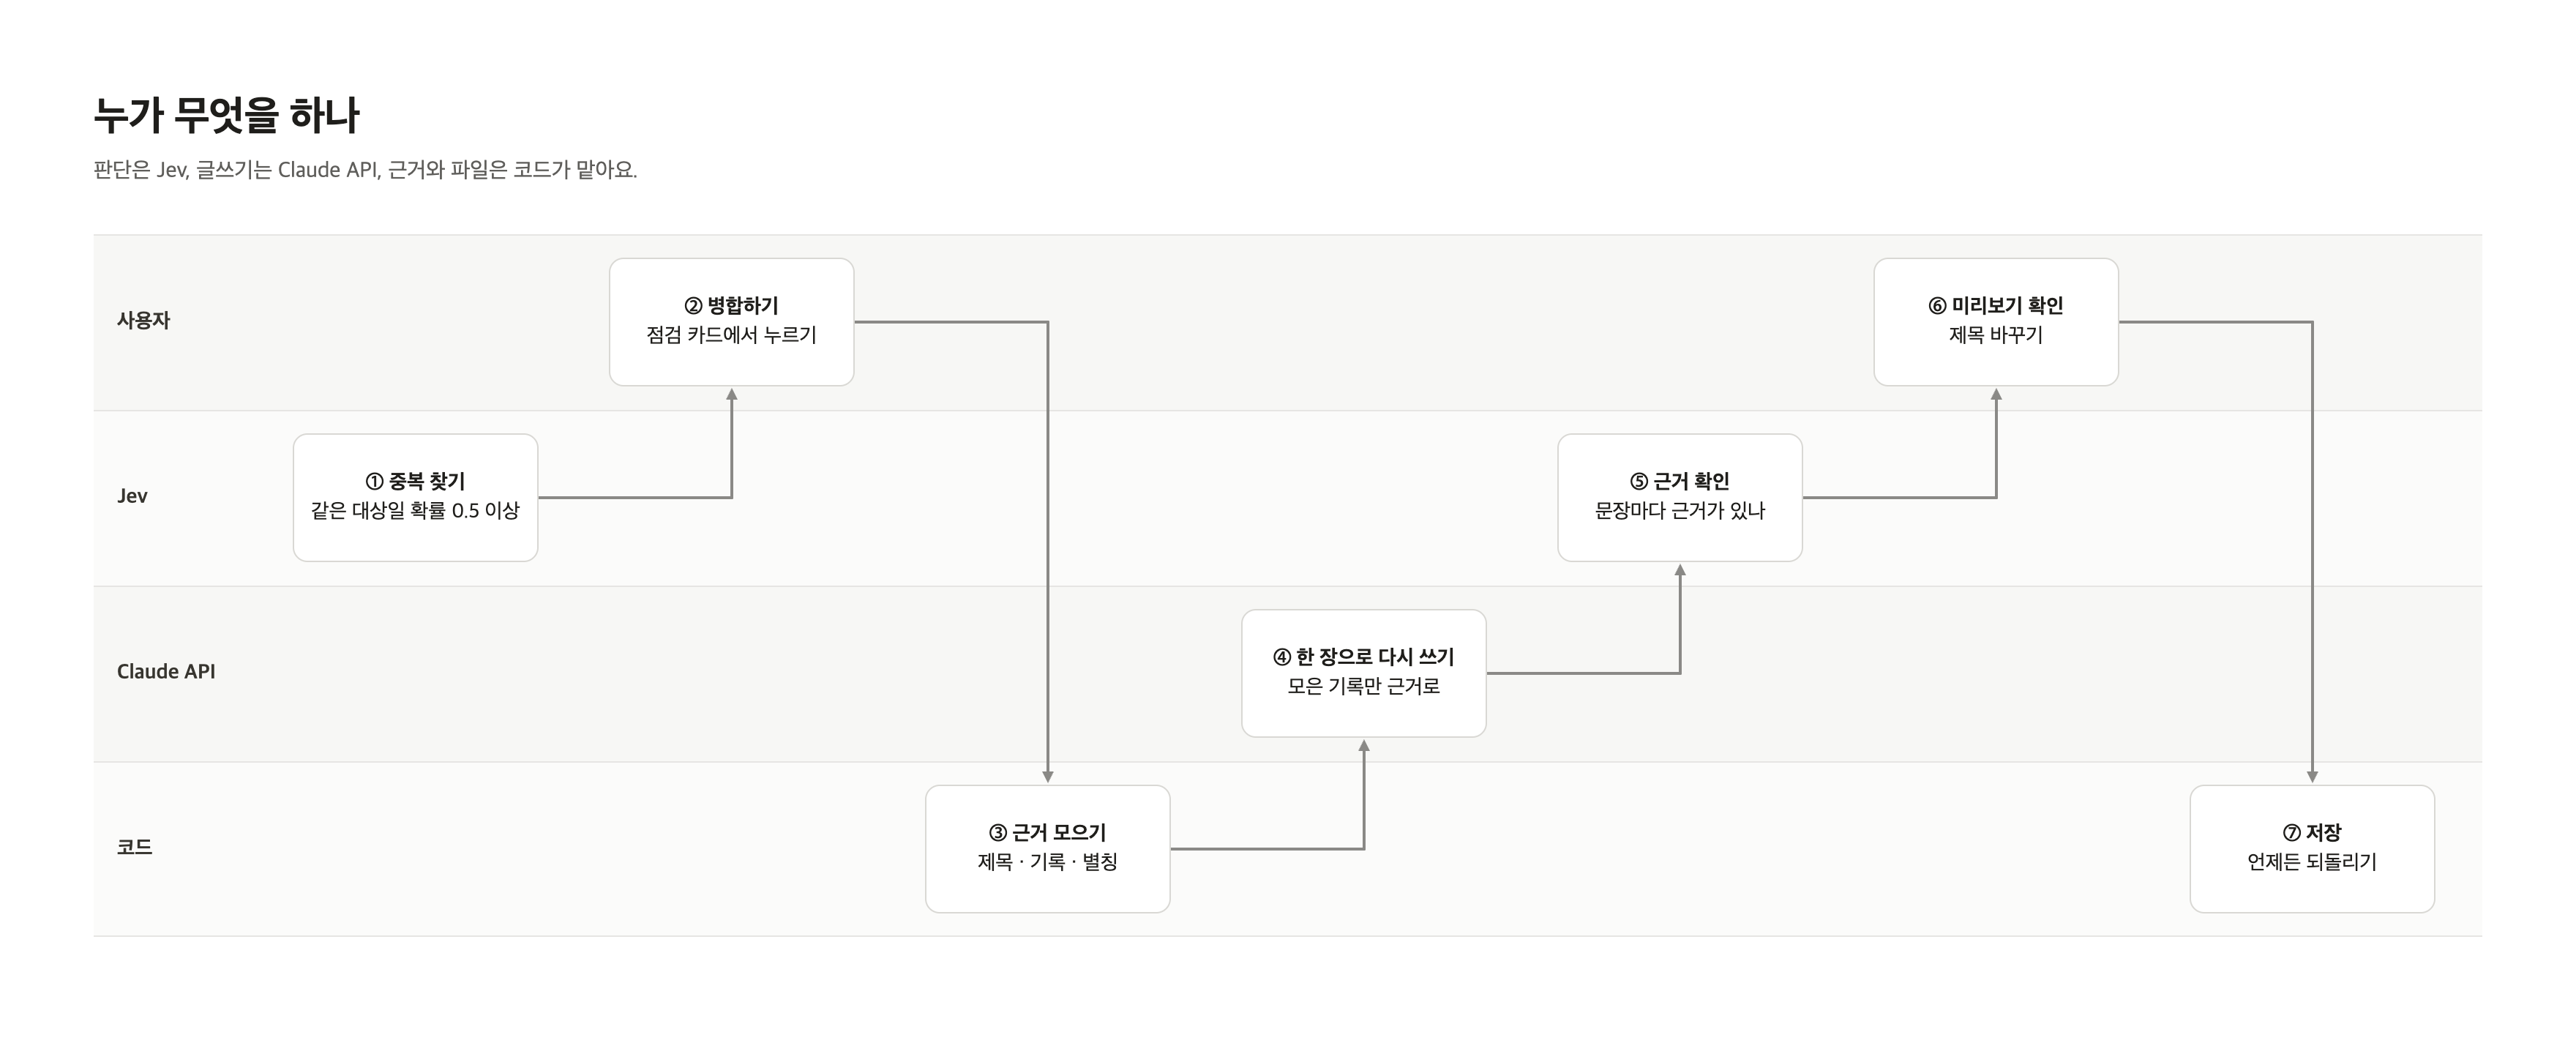

In [17]:
display(Image(filename="images/04_flow.png", width=900))

## 결론
---

| 질문 | 결과 |
|---|---|
| RQ1 같은 대상 찾기 | Jev(0.5 이상): 3쌍을 찾았고 잘못 찾은 쌍 0. 글자 유사도: 정답 3쌍을 다 잡으려면 8쌍을 찾고 그중 5쌍이 틀림 |
| RQ2 쓸 수 있는 요점 수 (지표 2) | 네 질문 합계 병합 전 7/15 → 병합 뒤 15/15 |
| RQ3 근거 확인 | Claude 문장 11개 모두 통과. 일부러 넣은 문장 3개: 처음 질문 2개, 엄격한 질문 3개 걸러 냄. 새 문장 6개: 두 질문 모두 6개 걸러 냄 |

가설 가운데 사용자 없이 확인할 수 있는 부분은 이 데이터에서 맞았다. Jev는 글자 유사도가 놓치거나 거꾸로 짚는 쌍을 가려냈고, 병합하면 한 대상에 대해 쓸 수 있는 기록이 늘었고, 근거 없는 문장은 대부분 걸러졌다. 지표 1(정리된 비율)과 지표 3(되돌린 비율), 그리고 편의성이 올라가는지는 사용자 기록이 있어야 확인할 수 있다.

## 회고 (KPT)

### Keep
처음에는 글자가 비슷하면 같은 위키일 가능성도 높을 거라고 생각했다. 그래서 글자 유사도를 비교 기준으로 같이 돌렸는데 결과가 정반대였다. 가장 비슷하다고 나온 세 쌍이 교감신경과 부교감신경, 인플레이션과 디플레이션, 과적합과 과소적합이었고, 정작 합쳐야 할 러닝과 달리기는 7위였다. 비교 기준을 두지 않았다면 Jev가 왜 필요한지를 말로만 설명했을 것이다.

Claude가 기록에 없는 문장을 하나도 쓰지 않아서, 근거 확인이 제대로 거르는지 알 방법이 없었다. 그래서 가짜 문장을 직접 섞었다. 숫자를 바꾼 「주 5회 달린다」는 바로 걸렸는데 「마라톤 완주를 준비하고 있다」는 통과했다. 달리기 기록 옆에 두면 그럴듯해 보이는 문장이다. 틀린 말보다 그럴듯한 말이 더 위험하다는 것을 이 한 문장으로 알게 됐다.

### Problem
마라톤 문장을 잡으려고 질문을 고쳤고, 고친 질문은 그 문장을 걸렀다. 그런데 새로 만든 가짜 문장 6개로 다시 해 보니 두 질문의 결과가 똑같았다. 한 문장을 보고 질문을 고친 것이라, 고친 질문이 더 낫다고는 말할 수 없었다.

데이터 12장은 정답을 아는 내가 만들었다. 같은 대상인 쌍은 이름만 다르고 내용은 비슷하게 썼으니 Jev에게 쉬운 시험이었을 수 있다. 실제 노트에서 생기는 중복은 이보다 애매할 것이다.

가설의 지표 가운데 정리된 비율과 되돌린 비율, 그리고 편해졌는지는 사용자가 없으면 잴 수 없어서 계산식만 만들어 두었다. 지표 2도 답을 직접 만들지 않고, 찾은 페이지에 기록이 몇 개 있는지로 대신 셌다.

API 크레딧이 없어서 Claude는 Claude Code CLI로 불렀다. 처음에는 짧은 요청 하나에 32만 토큰이 실렸는데, CLI가 내 설정과 메모리를 같이 보내고 있었기 때문이다. 결과만 보고 넘어갔다면 몰랐을 비용이다.

### Try
실제 내 세컨드브레인에서 생긴 중복으로 다시 재 보고 싶다. 특히 선형회귀와 회귀분석처럼 한쪽이 다른 쪽을 포함하는 쌍을 Jev가 어떻게 판단하는지 궁금하다.

근거 확인에서는 「첨삭을 받은 뒤 서류에 합격했다」처럼 기록에서 넘겨짚은 문장이 문턱 가까이(0.41) 있었다. 이런 문장을 더 모아서 문턱을 다시 정하고 싶다.

친구 몇 명에게 병합 버튼을 직접 써 보게 해서, 실제로 몇 쌍을 병합하고 몇 번 되돌리는지 보고 싶다. 가설이 맞는지는 거기서 갈린다.